<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/exercise/Listeria_feature_importance_shap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [50]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [51]:
path = "/content/drive/MyDrive/MFDS/practice/synthetic_listeria_weather_3x.xlsx"

In [52]:
import pandas as pd

# Excel 파일의 각 시트를 df와 tf로 읽어들이기
df = pd.read_excel(path, sheet_name='synthetic_listeria_lims_data')
tf = pd.read_excel(path, sheet_name='synthetic_weather_daily_101d')

print("df (LIMS) 행 수:", len(df))
print("tf (Weather) 행 수:", len(tf))

df (LIMS) 행 수: 3000
tf (Weather) 행 수: 5564


In [53]:
def summarize_df(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame([
        {
            'Column': col,
            'Dtype': df[col].dtype,
            'N_Unique': df[col].nunique(),
            'Null_Count': df[col].isnull().sum(),
            'Null_Ratio(%)': round(df[col].isnull().mean() * 100, 2),
            'Sample_Values': df[col].dropna().unique()[:5].tolist()
        }
        for col in df.columns
    ])

In [54]:
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,lims_data_key,object,3000,0,0.00,"[O000728_25012600001_1_3, O002012_26072900002_..."
1,hazard_label,object,1,0,0.00,[리스테리아]
2,judge_result,object,2,0,0.00,"[불검출, 검출]"
3,src_route,object,2,0,0.00,"[overseas, domestic]"
4,data_source,object,1,0,0.00,[식약처]
5,expr_iem_nm,object,4,0,0.00,"[리스테리아 모노사이토제네스, Listeria monocytogenes, 리스테리아..."
6,result_value,object,8,0,0.00,"[음성, 불검출, 음성,음성,음성,음성,음성, 음성, 음성, 음성, 음성, 음성, ..."
7,result_value_num,float64,2,2988,99.60,"[0.0, 2.0]"
8,judge_stdr,object,3,2959,98.63,"[n=5, c=0, m=0/25g, 음성, n=5,c=0,m=0/25g]"
9,judge_stdr_num,float64,0,3000,100.00,[]


### **[source code click](https://www.kaggle.com/code/shakedzy/alone-in-the-woods-using-theil-s-u-for-survival)**

In [55]:
def conditional_entropy(x,y):
    # entropy of x given y
    y_counter = Counter(y)
    xy_counter = Counter(list(zip(x,y)))
    total_occurrences = sum(y_counter.values())
    entropy = 0
    for xy in xy_counter.keys():
        p_xy = xy_counter[xy] / total_occurrences
        p_y = y_counter[xy[1]] / total_occurrences
        entropy += p_xy * math.log(p_y/p_xy)
    return entropy

def theil_u(x,y):
    s_xy = conditional_entropy(x,y)
    x_counter = Counter(x)
    total_occurrences = sum(x_counter.values())
    p_x = list(map(lambda n: n/total_occurrences, x_counter.values()))
    s_x = ss.entropy(p_x)
    if s_x == 0:
        return 1
    else:
        return (s_x - s_xy) / s_x

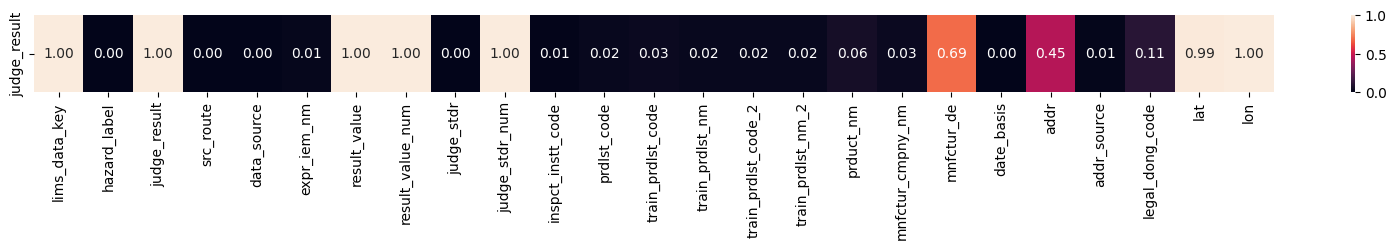

In [56]:
from collections import Counter
import math
import scipy.stats as ss
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_theils_u(data, figsize=(20, 1)):
    theilu = pd.DataFrame(index=['judge_result'], columns=data.columns)
    columns = data.columns
    for j in range(0, len(columns)):
        u = theil_u(data['judge_result'].tolist(), data[columns[j]].tolist())
        theilu.loc[:, columns[j]] = u
    theilu.fillna(value=np.nan, inplace=True)
    plt.figure(figsize=figsize)
    # .astype(float)를 추가하여 데이터 타입을 숫자로 명시적으로 변환합니다.
    sns.heatmap(theilu.astype(float), annot=True, fmt='.2f')
    plt.show()
    return

plot_theils_u(df)

In [57]:
selection_list = pd.read_excel("/content/drive/MyDrive/MFDS/practice/listeria_dataset_selection.xlsx")
selection_list[selection_list['feature 포함여부'] == 1]

,Unnamed: 0,Column,Dtype,feature 포함여부,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
2,2,judge_result,object,1,2,0,0.0,"['불검출', '검출']"
3,3,src_route,object,1,2,0,0.0,"['overseas', 'domestic']"
15,15,train_prdlst_nm_2,object,1,6,0,0.0,"['조리식품', '산양유', '아이스크림류', '수산물가공품', '치즈류']"
16,16,prduct_nm,object,1,20,0,0.0,"['수제 떡갈비 정식', '신선한 산양유 500ml', '초코 퍼지 바', '냉동 ..."
18,18,mnfctur_de,object,1,512,0,0.0,"['2025-01-26', '2026-07-29', '2026-01-25', '20..."
20,20,addr,object,1,769,0,0.0,"['충청북도 음성군 대소면 대풍산단로 88-65', '경상남도 양산시 유산공단7길 ..."
23,23,lat,float64,1,2978,0,0.0,"[36.993626, 35.345078, 35.354473, 35.3285, 36...."
24,24,lon,float64,1,2975,0,0.0,"[127.4584, 129.02031, 129.04005, 129.0041, 127..."


In [58]:
# @title **1. 예측에 필요한 컬럼만 추출하여 데이터셋 구성**
selection_list[selection_list['feature 포함여부'] == 1]['Column'].unique()
df = df[selection_list[selection_list['feature 포함여부'] == 1]['Column'].unique()].copy()
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,object,2,0,0.0,"[불검출, 검출]"
1,src_route,object,2,0,0.0,"[overseas, domestic]"
2,train_prdlst_nm_2,object,6,0,0.0,"[조리식품, 산양유, 아이스크림류, 수산물가공품, 치즈류]"
3,prduct_nm,object,20,0,0.0,"[수제 떡갈비 정식, 신선한 산양유 500ml, 초코 퍼지 바, 냉동 새우살, 자연..."
4,mnfctur_de,object,512,0,0.0,"[2025-01-26, 2026-07-29, 2026-01-25, 2025-03-1..."
5,addr,object,769,0,0.0,"[충청북도 음성군 대소면 대풍산단로 88-65, 경상남도 양산시 유산공단7길 19-..."
6,lat,float64,2978,0,0.0,"[36.993626, 35.345078, 35.354473, 35.3285, 36...."
7,lon,float64,2975,0,0.0,"[127.4584, 129.02031, 129.04005, 129.0041, 127..."


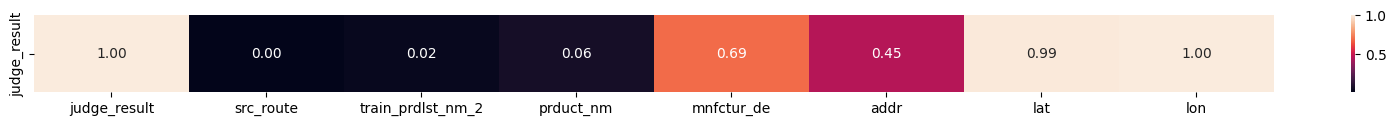

In [59]:
plot_theils_u(df)

In [60]:
print(f'prduct_nm(품목명)의 종류 : {len(df["prduct_nm"].unique())}')

prduct_nm(품목명)의 종류 : 20


In [61]:
# @title 2. 국내식품만 포함(수입식품은 제외)
df = df[df['src_route'] == 'domestic']
del df['src_route']

In [62]:
# @title 검출률(불량률)
df['judge_result'].value_counts(normalize=True)

,proportion
judge_result,
불검출,0.95358
검출,0.04642


In [63]:
df['mnfctur_de'] = pd.to_datetime(df['mnfctur_de'])

## **데이터 전처리**

### **1. addr(주소) 데이터 전처리**

In [64]:
# @title 1. 'addr' 컬럼의 문자열을 공백 기준으로 분할하여 '시도'와 '시군구'를 추출
# 데이터에 결측치나 비정상적인 주소가 있을 수 있으므로 string 타입으로 변환 후 처리
df['sido'] = df['addr'].astype(str).apply(lambda x: x.split()[0] if len(x.split()) > 0 else '')
df['sigungu'] = df['addr'].astype(str).apply(lambda x: x.split()[1] if len(x.split()) > 1 else '')
df['sido'].unique()

array(['경상남도', '경기도', '전북특별자치도', '전라남도', '충청북도', '강원특별자치도', '충청남도'],
      dtype=object)

### **3. 품목군별 Target Mean 적용**
- 데이터가 충분히 많기 떄문에 과거 부적합 비율을 사용해도 무방하다고 판단(Data Leakage는 없다고 판단)

In [65]:
# 원본 데이터 로드 시점의 'judge_result'를 안전하게 다시 가져오거나,
# 기존 값이 문자열인 경우에만 매핑을 적용하고 이미 숫자(0, 1)인 경우는 그대로 유지하도록 합니다.
import pandas as pd

# 안전한 변환을 위한 함수 정의
def safe_map_judge(val):
    if val == '불검출' or val == 0:
        return 0
    elif val == '검출' or val == 1:
        return 1
    return val

df['judge_result'] = df['judge_result'].apply(safe_map_judge)

print("df 'judge_result' 값 분포:")
print(df['judge_result'].value_counts(dropna=False))

df 'judge_result' 값 분포:
judge_result
0    2650
1     129
Name: count, dtype: int64


In [66]:
# train_prdlst_nm_2 단위로 judge_result의 평균값 계산하여 새로운 컬럼으로 추가
target_means = df.groupby('prduct_nm')['judge_result'].mean()
df['prduct_nm_tm'] = df['prduct_nm'].map(target_means)

### **3. 대한 민국을 pixel로 만들어 지역정보를 구분(위도 경도 정보 --> 격자 Grid)**
- 대한민국 정도의 좁은 지역에서는 위도·경도를 다음처럼 근사

> 위도 1° ≈ 111 km

> 경도 1° ≈ 88~92 km 정도

- **make_grid() 함수로 km 단위로 격자 셀을 생성하여 시계열정보와 연계하여 예측 가능**

> **10km, 30km, 50km 등등 Hyperparameter Tunning 실행**

> **기후정보와 join시 위도와 경도가 같은 grid 이면 Join하여 사용**


In [67]:
import geopandas as gpd

def make_grid(df, km, lon_col='lon', lat_col='lat'):
    gdf = gpd.GeoDataFrame(
        df.copy(),
        geometry=gpd.points_from_xy(df[lon_col], df[lat_col]),
        crs='EPSG:4326'
    ).to_crs('EPSG:5179')

    size = km * 1000
    gdf['grid_x'] = (gdf.geometry.x // size).astype(int)
    gdf['grid_y'] = (gdf.geometry.y // size).astype(int)
    gdf['Grid_ID'] = gdf['grid_x'].astype(str) + '_' + gdf['grid_y'].astype(str)

    return gdf

In [68]:
# @title 10 km × 10 km 크기의 격자 중에서 97번째 × 188번째 위치
df = make_grid(df, 10)                                   # 소문자 lon, lat
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,int64,2,0,0.0,"[0, 1]"
1,train_prdlst_nm_2,object,6,0,0.0,"[산양유, 조리식품, 아이스크림류, 수산물가공품, 치즈류]"
2,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
3,mnfctur_de,datetime64[ns],492,0,0.0,"[2026-07-29 00:00:00, 2026-01-25 00:00:00, 202..."
4,addr,object,766,0,0.0,"[경상남도 양산시 유산공단7길 19-14, 경상남도 양산시 유산공단7길 19-74,..."
5,lat,float64,2760,0,0.0,"[35.345078, 35.354473, 35.3285, 36.960964, 35...."
6,lon,float64,2759,0,0.0,"[129.02031, 129.04005, 129.0041, 127.227005, 1..."
7,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
8,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"
9,prduct_nm_tm,float64,19,0,0.0,"[0.10619469026548672, 0.029940119760479042, 0...."


### **4. 제품명에 대한 text mining으로 feature 생성**
- LLM에게 제품명에 대해 부적합비율과 관련성이 높은 text를 clustering prompt

In [69]:
df['prduct_nm'].unique()

array(['신선한 산양유 500ml', '수제 떡갈비 정식', '초코 퍼지 바', '냉동 새우살', '자연숙성 체다치즈',
       '까망베르 치즈', '모짜렐라 스트링치즈', '훈제오리 구이', '불고기 도시락', '바닐라 빈 아이스크림',
       '손질 연어 필렛', '렌위치 NY 샌드위치', '유기농 저온살균 우유', '망고 셔벗', '숲속산양목장 산양유',
       '훈제연어 샐러드', '삼치(국내산_해동,전처리,세척전)', '모듬 해물파전', '참치마요 삼각김밥',
       '치킨랩 샌드위치'], dtype=object)

In [70]:
import re

# (공정 분류, 키워드 정규식) - 위에서부터 우선 적용
LISTERIA_RULES = [
    ('훈제(비가열/냉훈 포함)',   r'훈제'),
    ('냉동 디저트',              r'아이스크림|셔벗|퍼지\s*바|아이스바|빙과'),
    ('숙성·연질 치즈',           r'체다|까망베르|브리|숙성.*치즈|블루치즈'),
    ('프레시·가공 치즈',         r'치즈'),
    ('액상 유제품(살균)',        r'우유|산양유|저온살균|요거트|요구르트'),
    ('수산 원료(가열조리 전)',   r'연어|삼치|새우|참치(?!마요)|고등어|오징어|굴|조개|해동|전처리'),
    ('조리 후 냉장·즉석섭취(RTE)', r'도시락|샌드위치|샌드위|삼각김밥|샐러드|김밥|정식|떡갈비|파전|랩'),
]

def classify_listeria_process(name: str) -> str:
    if not isinstance(name, str):
        return '미분류'
    for label, pattern in LISTERIA_RULES:
        if re.search(pattern, name):
            return label
    return '기타'

In [71]:
df['listeria_process'] = df['prduct_nm'].apply(classify_listeria_process)
df['listeria_process'].value_counts()

,count
listeria_process,
조리 후 냉장·즉석섭취(RTE),665
수산 원료(가열조리 전),475
냉동 디저트,467
액상 유제품(살균),464
숙성·연질 치즈,290
훈제(비가열/냉훈 포함),247
프레시·가공 치즈,171


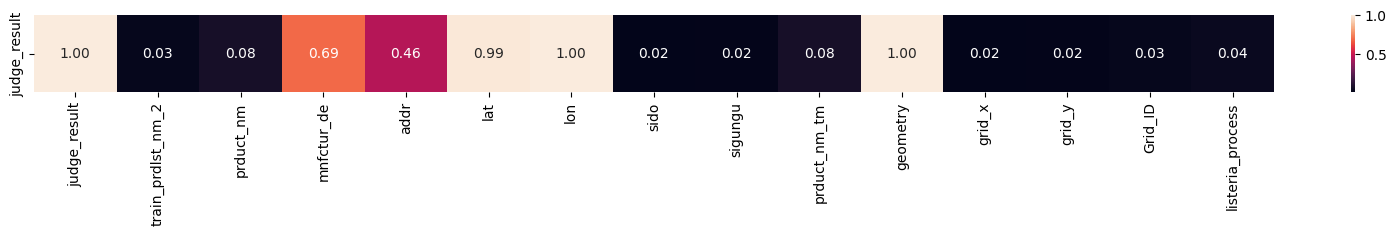

In [72]:
plot_theils_u(df)

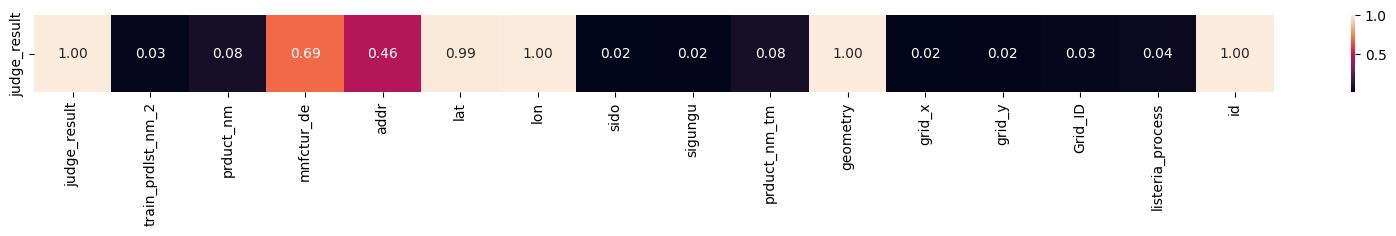

In [73]:
# @title 일련번호는 1.00 관련성 즉 그냥 외워버린다는 것, 그래서 제거
df['id'] = np.arange(len(df))
plot_theils_u(df)

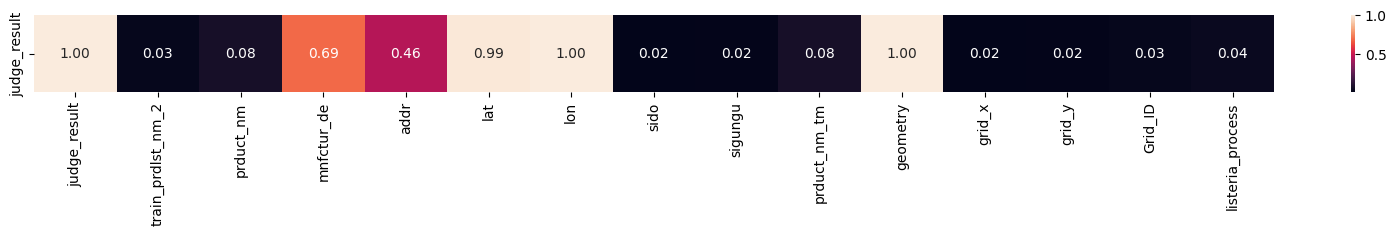

In [74]:
df.drop(columns='id', inplace=True)
plot_theils_u(df)

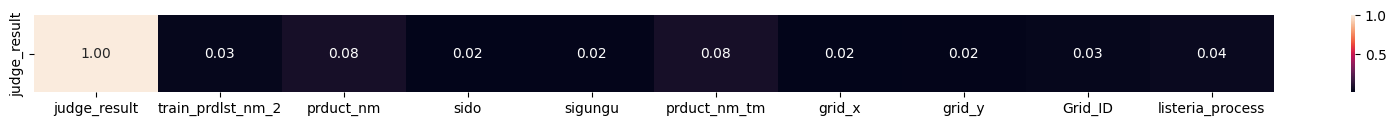

In [75]:
# @title **예측에 필요없는 feature 제거**
df.drop(columns=['mnfctur_de', 'addr', 'lat', 'lon', 'geometry'], inplace=True)
plot_theils_u(df)

In [76]:
# df = df.set_index('mnfctur_de').sort_index()

In [77]:
summarize_df(df)

,Column,Dtype,N_Unique,Null_Count,Null_Ratio(%),Sample_Values
0,judge_result,int64,2,0,0.0,"[0, 1]"
1,train_prdlst_nm_2,object,6,0,0.0,"[산양유, 조리식품, 아이스크림류, 수산물가공품, 치즈류]"
2,prduct_nm,object,20,0,0.0,"[신선한 산양유 500ml, 수제 떡갈비 정식, 초코 퍼지 바, 냉동 새우살, 자연..."
3,sido,object,7,0,0.0,"[경상남도, 경기도, 전북특별자치도, 전라남도, 충청북도]"
4,sigungu,object,8,0,0.0,"[양산시, 안성시, 익산시, 이천시, 여수시]"
5,prduct_nm_tm,float64,19,0,0.0,"[0.10619469026548672, 0.029940119760479042, 0...."
6,grid_x,int64,11,0,0.0,"[113, 97, 96, 99, 98]"
7,grid_y,int64,9,0,0.0,"[170, 188, 177, 191, 163]"
8,Grid_ID,object,16,0,0.0,"[113_170, 97_188, 96_177, 99_191, 98_191]"
9,listeria_process,object,7,0,0.0,"[액상 유제품(살균), 조리 후 냉장·즉석섭취(RTE), 냉동 디저트, 수산 원료(..."


In [78]:
df.columns

Index(['judge_result', 'train_prdlst_nm_2', 'prduct_nm', 'sido', 'sigungu',
       'prduct_nm_tm', 'grid_x', 'grid_y', 'Grid_ID', 'listeria_process'],
      dtype='object')

In [79]:
# @title **컬럼 구분**
num_cols  = ['prduct_nm_tm']
cat_cols  = ['train_prdlst_nm_2','prduct_nm', 'sido', 'sigungu', 'grid_x', 'grid_y', 'Grid_ID','listeria_process']
date_cols = ['mnfctur_de']

In [80]:
# @title 데이터전처리 후 알고리즘과 pipe 만들기

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# 1) X / y 분리 후 split
X = df.drop(columns='judge_result')
y = df['judge_result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2) 컬럼 구분

# 3) 제조일자 -> 연/월/요일 (고유값 492개라 그대로 원-핫 하면 안 됨)
def extract_date_parts(X):
    d = pd.to_datetime(X.iloc[:, 0], errors='coerce')
    return pd.DataFrame({'mfr_year': d.dt.year,
                         'mfr_month': d.dt.month,
                         'mfr_dow': d.dt.dayofweek})

def date_feature_names(transformer, input_features):
    return np.array(['mfr_year', 'mfr_month', 'mfr_dow'])

# 4) 전처리기
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore')),
])

date_pipe = Pipeline([
    ('extract', FunctionTransformer(extract_date_parts, feature_names_out=date_feature_names)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

preprocessor = ColumnTransformer([
    ('num',  num_pipe,  num_cols),
    ('cat',  cat_pipe,  cat_cols),
    ('date', date_pipe, date_cols),
])

### **6. 전체 모델 평가**

In [81]:
!pip install catboost -q

In [82]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

from scipy.sparse import csr_matrix, hstack
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
# Gradient Boosting 계열 모델
import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

from tqdm import tqdm

### **불균형데이터 특성 반영 전체 모델 평가(휴리스틱 수동 설정)**
- 불균형 가중치 조정: 전체 ratio를 그대로 쓰면 과잉검출(FP)이 수천 건 급증하므로, scale_pos_weight 지수를 완화 조율
- 모델 복잡도 제한: max_depth, num_leaves, min_child_samples, min_samples_leaf 등을 통해 트리 깊이를 제한하여 FP 발생을 억제
- F1-Score 기반 임계값(Threshold) 자동 탐색: 고정 $0.5$ 임계값 대신 Precision-Recall 커브에서 F1-Score가 최대가 되는 최적의 임계값을 찾아 분류 기준으로 적용할 수있음

In [83]:
# @title **예측모델 정의**
ratio = (len(y_train) - sum(y_train)) / sum(y_train)

models = {
    'LightGBM': lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=7,
        class_weight='balanced',
        random_state=42,
        verbose=-1,
        n_jobs=-1,
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        scale_pos_weight=ratio,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss',
    ),
    'CatBoost': CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        scale_pos_weight=ratio,
        random_state=42,
        verbose=0,
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=150, class_weight='balanced', random_state=42, n_jobs=-1
    ),
        'Extra Trees': ExtraTreesClassifier(
        n_estimators=150, class_weight='balanced', random_state=42, n_jobs=-1
    ),
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ),
}

In [84]:
# @title 예측모델 Hypeparameter

from scipy.stats import randint, uniform, loguniform

param_space = {
    'LightGBM': {'model__n_estimators': randint(200, 600),
                 'model__learning_rate': loguniform(0.01, 0.2),
                 'model__max_depth': randint(3, 12),
                 'model__num_leaves': randint(15, 80),
                 'model__subsample': uniform(0.6, 0.4),
                 'model__colsample_bytree': uniform(0.6, 0.4)},
    'XGBoost':  {'model__n_estimators': randint(200, 600),
                 'model__learning_rate': loguniform(0.01, 0.2),
                 'model__max_depth': randint(3, 10),
                 'model__subsample': uniform(0.6, 0.4),
                 'model__colsample_bytree': uniform(0.6, 0.4)},
    'CatBoost': {'model__iterations': randint(200, 600),
                 'model__learning_rate': loguniform(0.01, 0.2),
                 'model__depth': randint(4, 10),
                 'model__l2_leaf_reg': uniform(1, 9)},
    'Random Forest': {'model__n_estimators': randint(100, 400),
                      'model__max_depth': [None, 5, 10, 20],
                      'model__min_samples_leaf': randint(1, 10)},
    'Extra Trees':   {'model__n_estimators': randint(100, 400),
                      'model__max_depth': [None, 5, 10, 20],
                      'model__min_samples_leaf': randint(1, 10)},
    'Logistic Regression': {'model__C': loguniform(1e-3, 1e2),
                            'model__penalty': ['l2']},
}

In [85]:
# @title **주요 모델 추가**
from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              AdaBoostClassifier, BaggingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier

# ── 모델 추가 ──
models.update({
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Bagging': BaggingClassifier(random_state=42, n_jobs=-1),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'SVM (RBF)': SVC(probability=True, class_weight='balanced', random_state=42),
    'KNN': KNeighborsClassifier(n_jobs=-1),
    'MLP': MLPClassifier(max_iter=500, early_stopping=True, random_state=42),
    'Naive Bayes': GaussianNB(),
})

# ── 탐색 공간 추가 ──
param_space.update({
    'Gradient Boosting': {'model__n_estimators': randint(100, 400),
                          'model__learning_rate': loguniform(0.01, 0.2),
                          'model__max_depth': randint(2, 6),
                          'model__subsample': uniform(0.6, 0.4)},
    'HistGradientBoosting': {'model__learning_rate': loguniform(0.01, 0.2),
                             'model__max_iter': randint(100, 500),
                             'model__max_leaf_nodes': randint(15, 63),
                             'model__l2_regularization': loguniform(1e-3, 10)},
    'AdaBoost': {'model__n_estimators': randint(50, 400),
                 'model__learning_rate': loguniform(0.01, 1.0)},
    'Bagging': {'model__n_estimators': randint(20, 200),
                'model__max_samples': uniform(0.5, 0.5)},
    'Decision Tree': {'model__max_depth': randint(3, 15),
                      'model__min_samples_leaf': randint(1, 20)},
    'SVM (RBF)': {'model__C': loguniform(1e-2, 1e2),
                  'model__gamma': loguniform(1e-4, 1e0)},
    'KNN': {'model__n_neighbors': randint(3, 31),
            'model__weights': ['uniform', 'distance']},
    'MLP': {'model__hidden_layer_sizes': [(64,), (128,), (64, 32)],
            'model__alpha': loguniform(1e-5, 1e-1),
            'model__learning_rate_init': loguniform(1e-4, 1e-2)},
    'Naive Bayes': {'model__var_smoothing': loguniform(1e-10, 1e-5)},
})

# GaussianNB, LDA 등은 희소행렬을 받지 못하므로 전처리 출력을 dense로 고정
preprocessor.set_params(sparse_threshold=0)

ColumnTransformer(sparse_threshold=0,
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['prduct_nm_tm']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['train_prdlst_nm_2', 'prduct_nm', 'sido',
                                  'sigungu', 'grid_x', 'grid_y', 'Grid_ID',
                                  'listeria_process']),
                                ('date',
                                 Pipeline(steps=[('extract',
                                                  FunctionTransformer(feature_names_out=<function date_feature_names at 0x7fc5b435bba0>,
                                                                      func=<function extract_date_parts at 0x7fc5b435bc40>)),
                                                 ('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['mnfctur_de'])])

In [86]:
preprocessor

ColumnTransformer(sparse_threshold=0,
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['prduct_nm_tm']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['train_prdlst_nm_2', 'prduct_nm', 'sido',
                                  'sigungu', 'grid_x', 'grid_y', 'Grid_ID',
                                  'listeria_process']),
                                ('date',
                                 Pipeline(steps=[('extract',
                                                  FunctionTransformer(feature_names_out=<function date_feature_names at 0x7fc5b435bba0>,
                                                                      func=<function extract_date_parts at 0x7fc5b435bc40>)),
                                                 ('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['mnfctur_de'])])

In [92]:
for name, model in tqdm(models.items()):
    print(name, model.get_params())
    print('\n')

100%|██████████| 15/15 [00:00<00:00, 2727.71it/s]

LightGBM {'boosting_type': 'gbdt', 'class_weight': 'balanced', 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.05, 'max_depth': 7, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 300, 'n_jobs': -1, 'num_leaves': 31, 'objective': None, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbose': -1}


XGBoost {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 6, 'ma

In [94]:
# @title **1. No Hyperparameter Learning(Fitting)**
results = []
trained_pipes = {} # 학습된 파이프라인 저장용

for name, model in tqdm(models.items()):
    pipe = Pipeline([('prep', preprocessor_fixed), ('model', model)])

    # 1. 교차 검증 수행
    scores = cross_val_score(pipe,
                             X_train, y_train,
                             cv=3,
                             scoring='average_precision')
    cv_mean = scores.mean()
    print(f"{name} CV PR-AUC: {cv_mean:.4f}")

    # 2. 전체 학습 데이터로 모델 학습 (필수 추가!)
    pipe.fit(X_train, y_train)
    trained_pipes[name] = pipe # 모델 이름으로 저장

    # 3. 테스트셋 평가
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    p, r, _ = precision_recall_curve(y_test, prob)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    # 4. results에 CV 평균 점수 함께 저장
    results.append({
        'Model': name,
        'CV_PR-AUC': cv_mean,  # <-- 여기에 저장됩니다
        'Test_PR-AUC': auc(r, p),
        '오류건수(FN+FP)': fn + fp,
        '오탐비율(%)': (fn + fp) / len(y_test) * 100, # * 기호 복구
        '미검출(FN)': fn,
        '과잉검출(FP)': fp,
        'ROC-AUC': roc_auc_score(y_test, prob),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'Precision': precision_score(y_test, pred, zero_division=0),
    })

summary = (pd.DataFrame(results)
           .sort_values('Test_PR-AUC', ascending=False)
           .reset_index(drop=True))
summary

  0%|          | 0/15 [00:00<?, ?it/s]

LightGBM CV PR-AUC: 0.2000


  7%|▋         | 1/15 [00:02<00:35,  2.52s/it]

XGBoost CV PR-AUC: 0.2082


 13%|█▎        | 2/15 [00:09<01:08,  5.28s/it]

CatBoost CV PR-AUC: 0.1934


... (15 outputs left out)

KNN CV PR-AUC: 0.1348
MLP CV PR-AUC: 0.0760


100%|██████████| 15/15 [00:29<00:00,  1.94s/it]

Naive Bayes CV PR-AUC: 0.0587


,Model,CV_PR-AUC,Test_PR-AUC,오류건수(FN+FP),오탐비율(%),미검출(FN),과잉검출(FP),ROC-AUC,F1-Score,Recall,Precision
0,Naive Bayes,0.058673,0.482632,471,84.712230,2,469,0.672424,0.092486,0.923077,0.048682
1,Random Forest,0.166456,0.244686,81,14.568345,10,71,0.872823,0.283186,0.615385,0.183908
2,SVM (RBF),0.172652,0.231133,97,17.446043,4,93,0.836212,0.312057,0.846154,0.191304
3,LightGBM,0.199986,0.216013,108,19.424460,4,104,0.876343,0.289474,0.846154,0.174603
4,CatBoost,0.193371,0.215414,108,19.424460,4,104,0.877286,0.289474,0.846154,0.174603
5,XGBoost,0.208159,0.201841,108,19.424460,4,104,0.847968,0.289474,0.846154,0.174603
6,HistGradientBoosting,0.197711,0.197399,110,19.784173,4,106,0.862046,0.285714,0.846154,0.171875
7,Decision Tree,0.192742,0.182390,108,19.424460,4,104,0.837228,0.289474,0.846154,0.174603
8,Bagging,0.191751,0.182273,28,5.035971,25,3,0.834361,0.066667,0.038462,0.250000
9,Extra Trees,0.200060,0.182078,108,19.424460,4,104,0.836792,0.289474,0.846154,0.174603


### **학습된 예측모델에서 RF로 SHAP 분석**

In [95]:
trained_pipes

{'LightGBM': Pipeline(steps=[('prep',
                  ColumnTransformer(sparse_threshold=0,
                                    transformers=[('num',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(strategy='median')),
                                                                   ('scaler',
                                                                    StandardScaler())]),
                                                   ['prduct_nm_tm']),
                                                  ('cat',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(strategy='most_frequent')),
                                                                   ('onehot',
                                                                    OneHotEncoder(handle_unknown='ignore

In [96]:
trained_pipes.keys()

dict_keys(['LightGBM', 'XGBoost', 'CatBoost', 'Random Forest', 'Extra Trees', 'Logistic Regression', 'Gradient Boosting', 'HistGradientBoosting', 'AdaBoost', 'Bagging', 'Decision Tree', 'SVM (RBF)', 'KNN', 'MLP', 'Naive Bayes'])

In [98]:
# @title **RF 학습된 모델(파란색)**
trained_pipes['Random Forest']

Pipeline(steps=[('prep',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['prduct_nm_tm']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['train_prdlst_nm_2',
                                                   'prduct_nm', 'sido',
                                                   'sigungu', 'grid_x',
                                                   'grid_y', 'Grid_ID',
                                                   'listeria_process'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=150, n_jobs=-1,
                                        random_state=42))])

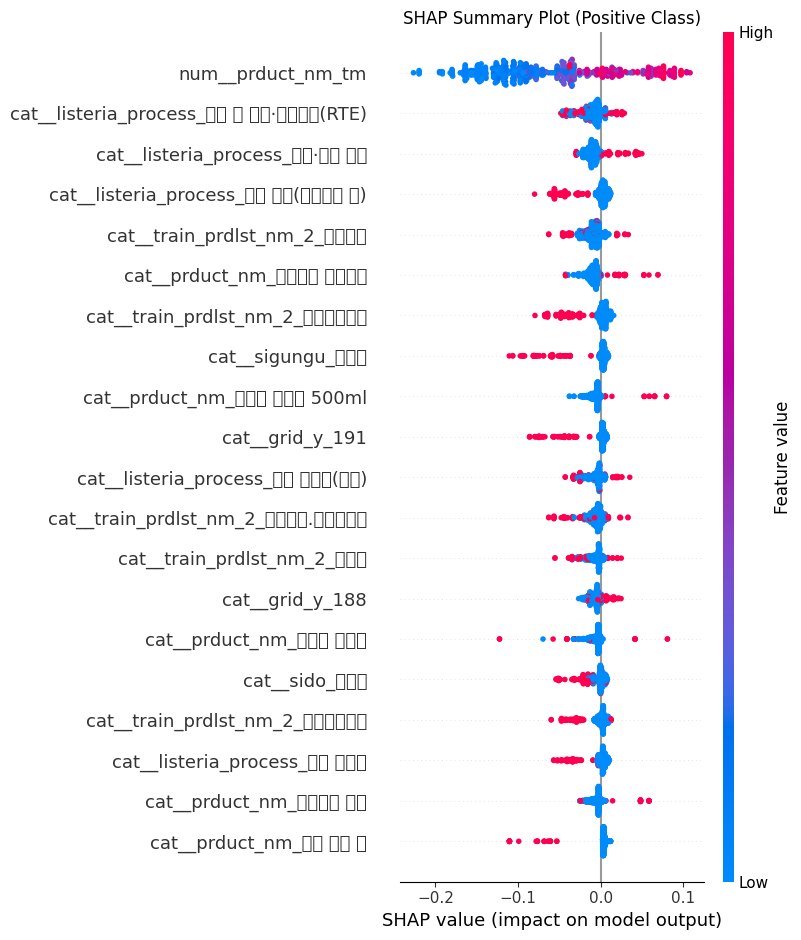

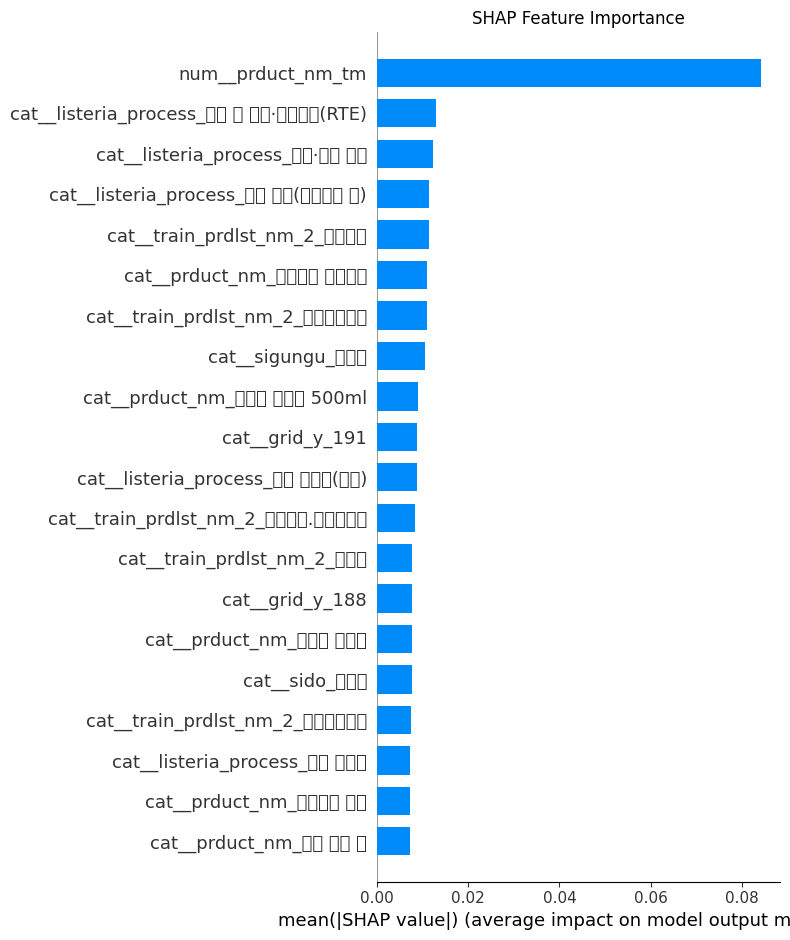

In [100]:
import shap
import matplotlib.pyplot as plt

# 1. 학습된 Random Forest 파이프라인 꺼내기 (models 딕셔너리의 키 이름에 맞게 수정)
rf_pipe = trained_pipes['Random Forest'] # 예: 'rf' 또는 'RandomForest'

# 2. 파이프라인에서 전처리된 X_test 데이터와 최종 모델 분리
preprocessor = rf_pipe.named_steps['prep']
rf_model = rf_pipe.named_steps['model']

X_test_transformed = preprocessor.transform(X_test)
# 전처리 후 생성된 피처 이름 추출 (원-핫 인코딩 등 반영)
feature_names = preprocessor.get_feature_names_out()

# (선택) 데이터가 너무 많아 느릴 경우 샘플링 (예: 500개만 추출)
# X_test_transformed = X_test_transformed[:500]

# 3. TreeExplainer 생성 및 SHAP 값 계산
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_transformed)

# 4. 이진 분류(Binary Classification)일 경우 Positive 클래스(1)의 SHAP 값 추출
# (shap 버전에 따라 반환 형태가 리스트일 수도, 3차원 배열일 수도 있어 분기 처리)
if isinstance(shap_values, list):
    shap_values_pos = shap_values[1]
elif shap_values.ndim == 3:
    shap_values_pos = shap_values[:, :, 1]
else:
    shap_values_pos = shap_values

# 5. 시각화 (1) Summary Plot (Beeswarm - 피처별 영향력 및 방향성)
plt.title("SHAP Summary Plot (Positive Class)")
shap.summary_plot(shap_values_pos, X_test_transformed, feature_names=feature_names)

# 6. 시각화 (2) Bar Plot (전체적인 피처 중요도 순위)
plt.title("SHAP Feature Importance")
shap.summary_plot(shap_values_pos, X_test_transformed, feature_names=feature_names, plot_type="bar")

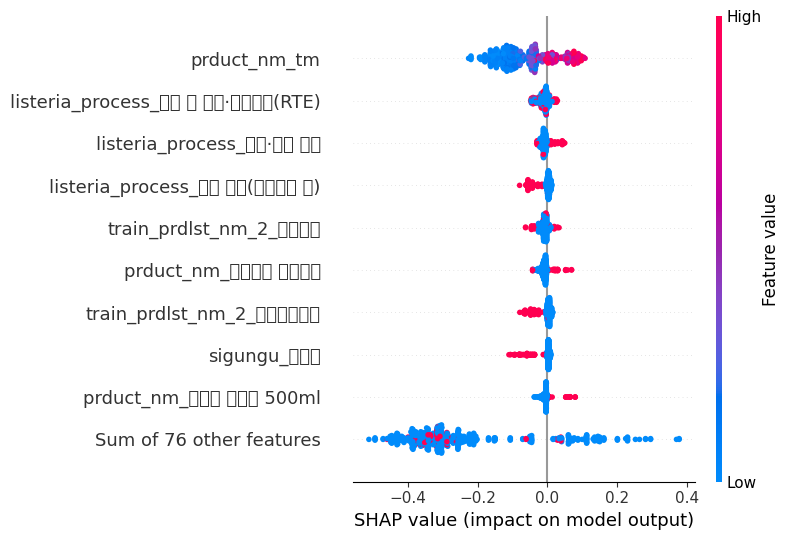

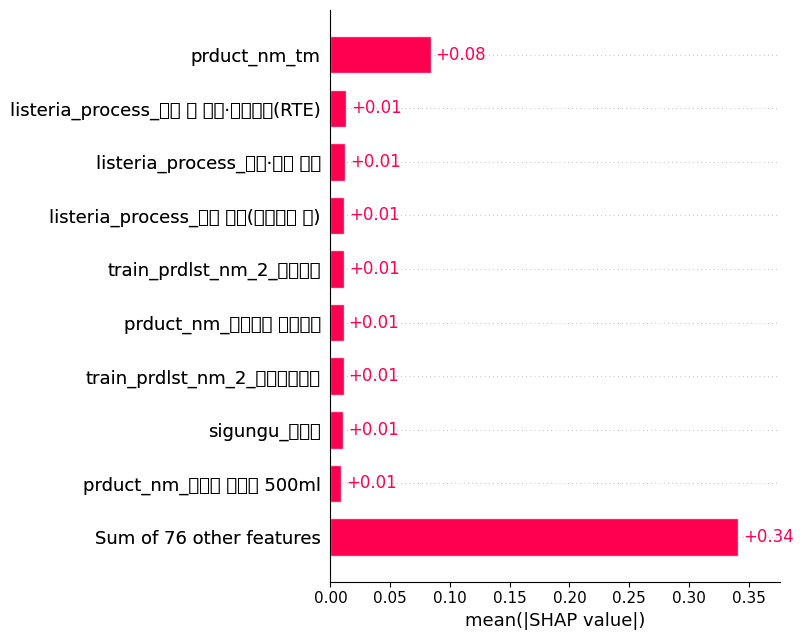

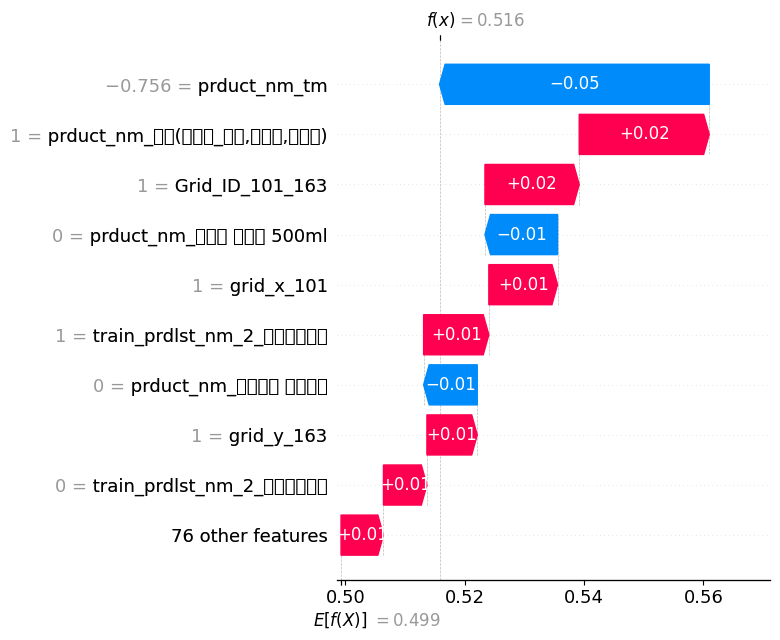

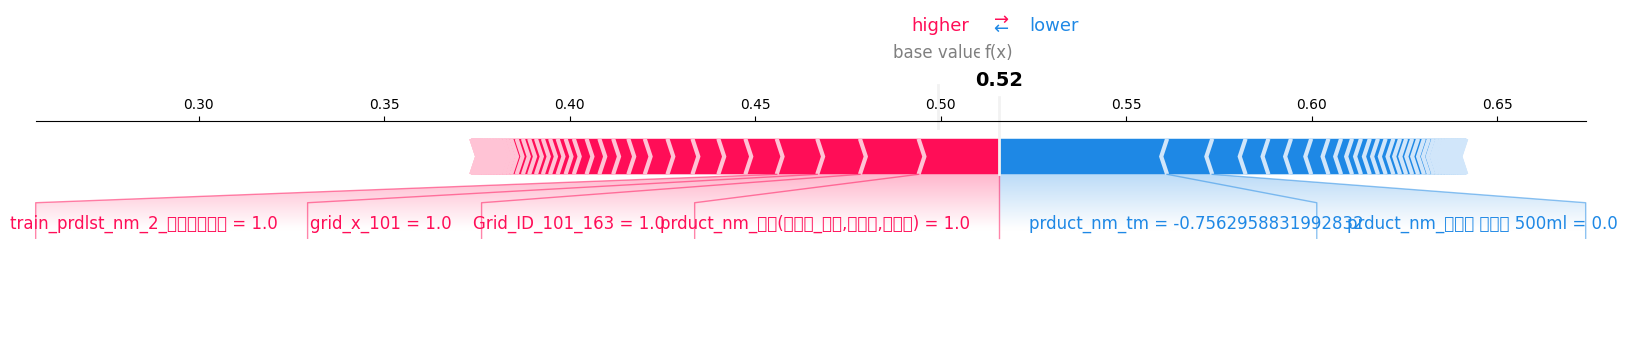

In [108]:
import shap
import matplotlib.pyplot as plt

# 1. 파이프라인 분리
pipe = trained_pipes['Random Forest']
prep, model = pipe.named_steps['prep'], pipe.named_steps['model']

# 2. 테스트 데이터 변환 (희소행렬이면 dense로)
X = prep.transform(X_test)
X = X.toarray() if hasattr(X, "toarray") else X
names = [n.split('__')[-1] for n in prep.get_feature_names_out()]

# 3. SHAP 값 계산 (이진 분류면 positive 클래스만)
sv = shap.TreeExplainer(model)(X)
if sv.values.ndim == 3:
    sv = sv[..., 1]
sv.feature_names = names  # sv.data는 이미 X로 채워져 있음

# 4. 그림 그리기 (전부 matplotlib 기반이라 JS 설정 불필요)
shap.plots.beeswarm(sv, show=False)   # 전체 피처 영향도
plt.tight_layout(); plt.show()

shap.plots.bar(sv, show=False)        # 평균 |SHAP| 중요도
plt.tight_layout(); plt.show()

shap.plots.waterfall(sv[0], show=False)  # 첫 번째 샘플 개별 설명
plt.tight_layout(); plt.show()

# Force plot도 정적 이미지로 출력
shap.plots.force(sv.base_values[0], sv.values[0], sv.data[0],
                 feature_names=names, matplotlib=True)

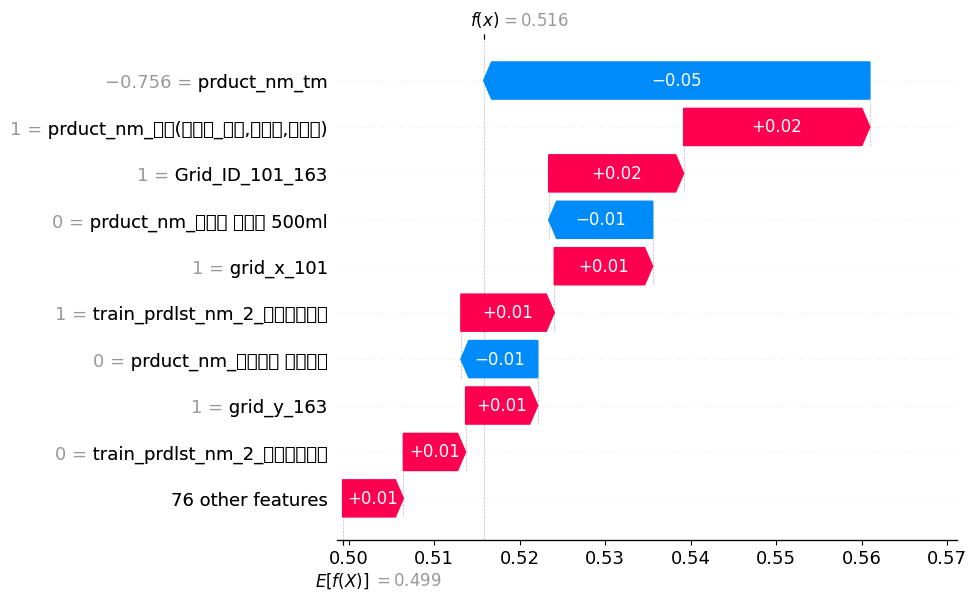

In [103]:
# 0번째 샘플에 대한 Waterfall Plot
idx = 0
shap.plots.waterfall(shap_exp_pos[idx])

In [105]:
# (1) 첫 번째 instance(0번 샘플)의 Force Plot (슬라이드 상단 그림)
shap.initjs()
shap.plots.force(shap_exp_pos[0])

In [107]:
# (2) 여러 instance의 Force Plot 누적 시각화 (슬라이드 하단 그림)
# 데이터가 너무 많으면 브라우저가 느려지므로 상위 50개 정도만 잘라서 그리는 것을 권장합니다.
shap.initjs()
shap.plots.force(shap_exp_pos[:50])

## **[Click](https://github.com/ancestor9/AI-with-python)하고 공부하시라 !**

In [88]:
# @title  **학습 및 검증데이터 예측**
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (precision_recall_curve, auc, confusion_matrix, roc_auc_score,
                             f1_score, recall_score, precision_score)
from sklearn.compose import ColumnTransformer

# num_cols와 cat_cols만 사용하여 preprocessor를 재정의합니다.
preprocessor_fixed = ColumnTransformer([
    ('num',  num_pipe,  num_cols),
    ('cat',  cat_pipe,  cat_cols),
], sparse_threshold=0)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results, best_models = [], {}

for name, model in tqdm(models.items()):
    # 수정된 전처리기를 사용합니다.
    pipe = Pipeline([('prep', preprocessor_fixed), ('model', model)])
    search = RandomizedSearchCV(
        pipe,
        param_space[name],

        n_iter=10,
        cv=cv,
        scoring='average_precision',   # PR-AUC 기준
        random_state=42, n_jobs=-1,
        refit=True,
        error_score='raise',
    )
    search.fit(X_train, y_train)
    best = search.best_estimator_
    best_models[name] = best

    # 테스트셋 평가
    prob = best.predict_proba(X_test)[:, 1]
    pred = best.predict(X_test)
    p, r, _ = precision_recall_curve(y_test, prob)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

    results.append({
        'Model': name,
        'CV PR-AUC': search.best_score_,
        'PR-AUC': auc(r, p),
        '오류건수(FN+FP)': fn + fp,
        '오탐비율(%)': (fn + fp) / len(y_test) * 100,
        '미검출(FN)': fn,
        '과잉검출(FP)': fp,
        'ROC-AUC': roc_auc_score(y_test, prob),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Best Params': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
    })
    print(f'{name} 완료 | CV PR-AUC={search.best_score_:.4f}')

summary = (pd.DataFrame(results)
           .sort_values('PR-AUC', ascending=False)
           .reset_index(drop=True))

display(summary.drop(columns='Best Params').round(4))

  0%|          | 0/15 [00:36<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
summary.sort_values('CV PR-AUC', ascending=False).round(0)

In [ ]:
print(y_train.sum(), y_test.sum())                    # 양성 개수
print(X_train.merge(X_test, how='inner').shape[0])    # train/test 중복 행 수

# prduct_nm_tm 제외하고 다시 돌려서 점수가 어떻게 변하는지 비교

In [ ]:
print(y_train.sum(), y_test.sum())                    # 양성 개수
print(X_train.merge(X_test, how='inner').shape[0])    # train/test 중복 행 수

# prduct_nm_tm 제외하고 다시 돌려서 점수가 어떻게 변하는지 비교

CV 점수는 "튜닝 과정에서 이 설정이 얼마나 좋았나"이고, 테스트 점수는 "새 데이터에서 실제로 얼마나 잘 맞히나"입니다. 보통 두 값이 비슷해야 정상입니다.

결과가 이상한 점

- CV PR-AUC는 0.78~0.81인데 테스트 PR-AUC는 거의 전부 1.0000(CatBoost는 오류 0건)입니다. 테스트가 CV보다 0.2 가까이 높은 것은 일반적인 일이 아니고, 아래 가능성을 의심해야 합니다.

> 누수 (가장 유력): 앞서 말씀드린 prduct_nm_tm이 전체 데이터(test 포함)로 계산한 제품명별 타깃 평균이라면, test 행의 정답 정보가 피처에 이미 들어 있습니다. 다만 이 경우 CV 점수도 부풀려지는 게 보통이라, 아래 2번과 함께 확인이 필요합니다.

> test와 train의 중복·유사 행: 같은 제품·지역·제조일 조합이 train과 test에 나뉘어 있으면 test가 쉬워집니다. X_test와 X_train의 중복 행 비율을 확인해 보세요.

> test 양성 수가 너무 적음: 양성이 몇 건 안 되면 PR-AUC가 1.0이 쉽게 나오고 변동도 큽니다. y_test.sum()을 확인하세요. 반대로 CV는 fold별 편차가 클 수 있어 search.cv_results_의 std_test_score도 같이 보면 좋습니다.

In [ ]:
# @title **Nested CV(Cross Validation)**
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone

inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)          # 튜닝용
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)    # 평가용

scoring = {
    'pr_auc': 'average_precision',
    'roc_auc': 'roc_auc',
    'f1': 'f1',
    'recall': 'recall',
    'precision': 'precision'
}

# 평가할 후보 모델 선택 (models 딕셔너리에 있는 이름 중 선택)
target_models = ['CatBoost', 'LightGBM', 'XGBoost', 'Random Forest']

nested_results = []
for name in tqdm(target_models):
    # 원본 models 딕셔너리를 건드리지 않도록 복제 후 내부 스레드 1로 조정
    est = clone(models[name])
    if 'n_jobs' in est.get_params():
        est.set_params(n_jobs=1)
    if name == 'CatBoost':
        est.set_params(thread_count=1)

    pipe = Pipeline([
        ('prep', clone(preprocessor)),
        ('model', est)
    ])

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_space[name],
        n_iter=10,
        cv=inner,
        scoring='average_precision',
        random_state=42,
        n_jobs=-1,
        error_score='raise',
    )

    # X, y 전체를 사용해 엄격한 일반화 성능 평가 (총 5-fold × 3-repeat = 15회 평가)
    cv_res = cross_validate(search, X, y, cv=outer, scoring=scoring, n_jobs=1)

    row = {'Model': name}
    for m in scoring:
        s = cv_res[f'test_{m}']
        row[m] = f'{s.mean():.3f} ± {s.std():.3f}'
    nested_results.append(row)
    print(f'{name} Nested CV 완료 | PR-AUC = {row["pr_auc"]}')

display(pd.DataFrame(nested_results))

- 15개의 서로 다른 최적 모델이 생기므로 배포용 단일 모델은 별도 재학습 필요
> 바깥 루프 15번마다 조금씩 다른 최적 하이퍼파라미터가 뽑힐 수 있으므로, Nested CV로 1등 알고리즘(예: CatBoost)을 확정한 뒤에는 전체 데이터(X, y)를 대상으로 일반 RandomizedSearchCV를 한 번 더 돌려 최종 배포용 단일 모델(best_estimator_)을 확정

In [ ]:
# @title **15회 outer 평가용**
pd.DataFrame(cv_res).sort_values('test_pr_auc', ascending=False).round(3)

In [ ]:
from IPython.display import Image, display
display(Image('/content/drive/MyDrive/MFDS/practice/Code_Generated_Image.png'))

- 실무 활용

> 1단계 (모델 선정): 데이터가 수천 건 이하일 때 Nested CV로 후보 알고리즘(CatBoost, LightGBM 등)들의 거품 없는 진짜 실력(PR-AUC 평균 ± 표준편차)을 비교해 최종 알고리즘 1개를 선정

> 2단계 (최종 모델 확정): 선정된 1등 알고리즘 하나만 가지고 전체 학습 데이터에서 일반 RandomizedSearchCV(refit=True)를 실행해 실제 예측에 쓸 최종 모델 객체를 저장

In [ ]:
# @title **Refit**
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import precision_recall_curve, classification_report, average_precision_score, roc_auc_score

# ==============================================================================
# 1. 최종 CatBoost 파이프라인 구성 (전체 학습 데이터 X_train, y_train 사용)
#    * 별도 홀드아웃 테스트셋이 없다면 X, y 전체를 넣어도 됩니다.
# ==============================================================================
final_catboost = clone(models['CatBoost'])
final_catboost.set_params(thread_count=-1)  # 단일 모델 튜닝이므로 전체 스레드 활용 가능

final_pipe = Pipeline([
    ('prep', clone(preprocessor)),
    ('model', final_catboost)
])

# 1단계에서 CatBoost로 알고리즘을 좁혔으므로 탐색 횟수(n_iter)를 30~50회로 늘려 정밀 탐색
cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

final_search = RandomizedSearchCV(
    estimator=final_pipe,
    param_distributions=param_space['CatBoost'],
    n_iter=30,
    cv=cv_final,
    scoring='average_precision',  # PR-AUC 기준 최적화
    random_state=42,
    n_jobs=1,                     # CatBoost가 thread_count=-1을 쓰므로 여기는 1로 설정
    refit=True,                   # 1등 파라미터로 X_train 전체 재학습
    error_score='raise'
)

final_search.fit(X_train, y_train)

# 확정된 최종 파이프라인 객체
best_catboost_model = final_search.best_estimator_
best_params = {k.replace('model__', ''): v for k, v in final_search.best_params_.items()}

print(f"최종 CV PR-AUC: {final_search.best_score_:.4f}")
print(f"확정된 최적 파라미터: {best_params}")

# ==============================================================================
# 2. 불균형 데이터용 최적 분류 임계값(Threshold) 산출 (OOF 예측 기반)
# ==============================================================================
oof_probs = cross_val_predict(
    best_catboost_model, X_train, y_train,
    cv=cv_final, method='predict_proba', n_jobs=1
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_probs)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)

best_idx = np.argmax(f1_scores)
best_threshold = float(thresholds[best_idx])

print(f"최적 임계값(Threshold): {best_threshold:.4f} (OOF 최대 F1 = {f1_scores[best_idx]:.4f})")

# ==============================================================================
# 3. 홀드아웃 테스트셋(X_test, y_test)이 있는 경우 최종 검증
# ==============================================================================
test_probs = best_catboost_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

print("\n[최종 모델 Test 성능 리포트]")
print(f"Test PR-AUC : {average_precision_score(y_test, test_probs):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")
print(classification_report(y_test, test_preds, target_names=['불검출(0)', '검출(1)'], digits=4))

# ==============================================================================
# 4. 운영/배포용 최종 모델 번들 저장 및 추론 예시
# ==============================================================================
model_artifact = {
    'pipeline': best_catboost_model,
    'threshold': best_threshold,
    'best_params': best_params,
    'feature_columns': list(X_train.columns)
}

joblib.dump(model_artifact, 'final_catboost_listeria_model.pkl')
print("저장 완료: final_catboost_listeria_model.pkl")

# --- [참고] 저장된 모델 불러와서 신규 데이터 예측하기 ---
# loaded = joblib.load('final_catboost_listeria_model.pkl')
# new_probs = loaded['pipeline'].predict_proba(X_new)[:, 1]
# new_preds = (new_probs >= loaded['threshold']).astype(int)

In [ ]:
# @title **decision threshhold visualization**
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

y_true, y_prob = np.asarray(y_train), np.asarray(oof_probs)

p, r, th = precision_recall_curve(y_true, y_prob)
df_th = pd.DataFrame({'threshold': th, 'precision': p[:-1], 'recall': r[:-1]})
df_th['f1'] = 2 * df_th.precision * df_th.recall / (df_th.precision + df_th.recall).clip(lower=1e-12)
df_th['pos_rate'] = [(y_prob >= t).mean() for t in df_th.threshold]

best = df_th.loc[df_th.f1.idxmax()]

fig, ax = plt.subplots(figsize=(15, 6), dpi=150)
for col, c, ls, lw in [('precision', '#2563EB', '-', 2), ('recall', '#16A34A', '-', 2),
                       ('f1', '#D97706', '-', 2.5), ('pos_rate', '#64748B', '--', 1.8)]:
    ax.plot(df_th.threshold, df_th[col], color=c, ls=ls, lw=lw, label=col)

ax.axvline(best.threshold, color='#EF4444', ls=':', lw=1.8,
           label=f'Best F1 th={best.threshold:.2f} (F1={best.f1:.3f})')
ax.axhline(y_true.mean(), color='#94A3B8', ls='-.', lw=1.2,
           label=f'Actual positive rate ({y_true.mean():.1%})')

ax.set(title='Precision / Recall / F1 / Positive Rate by Threshold',
       xlabel='Threshold', ylabel='Score / Rate', xlim=(0, 1), ylim=(0, 1.05))
ax.grid(True, ls='--', alpha=0.4)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=True)
plt.tight_layout(); plt.show()

print('*'*100)
display(df_th[df_th.threshold.between(best.threshold - 0.05, best.threshold + 0.05)].round(2))